[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Valores atípicos y transformaciones.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete · Módulo II: *Describir y comparar*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En este *notebook* se detectarán valores atípicos con la regla del IQR, el puntaje *z* y el puntaje *z* robusto, se decidirá si son errores o valores reales y se aplicará la transformación logarítmica a variables asimétricas.

## 🧭 Cómo usar este *notebook*.

* Ejecuta las celdas **en orden** (`Shift + Enter`).
* 🟢 **Ejercicio básico:** lo que todos deben dominar.
* 🔴 **Reto (opcional):** para quien termina antes o quiere profundizar. Si no da tiempo en clase, se puede resolver como práctica.
* Las celdas `# TU CÓDIGO AQUÍ` y *✍️ Tu respuesta* son para ti.

## 📚 Referencia de la API: curso py311.

Esta sesión usa métodos ya vistos en py311 sin repasarlos uno por uno: `quantile`, `value_counts` y `nlargest` en [py311 · 19 Herramientas de análisis de datos](https://github.com/PythonistaMX/py311/blob/main/19_herramientas_de_analisis_de_datos.ipynb); `transform` y `apply` en [py311 · 17 Los métodos `apply()` y `transform()`](https://github.com/PythonistaMX/py311/blob/main/17_metodos_apply_y_transform.ipynb); `groupby` en [py311 · 24 Métodos `groupby()`](https://github.com/PythonistaMX/py311/blob/main/24_metodos_groupby.ipynb); y las gráficas de distribución de *Seaborn* en [py311 · 31 Introducción a *Seaborn*](https://github.com/PythonistaMX/py311/blob/main/31_introduccion_a_seaborn.ipynb). El tiempo de la sesión se dedica a **decidir** qué medida describe mejor cada distribución y qué hacer con los atípicos.

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3, así que pueden verse diferencias (por ejemplo, texto como `object` en lugar de `str`, o el uso de `inplace=True`). Cuando difieran, se sigue lo que muestra este *notebook* (ver la sección 1.1 de `03_pandas_3_esencial.ipynb`).

### Preparación del entorno.

* La siguiente celda importará las bibliotecas, incluido el módulo `stats` de *SciPy*, y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)
from scipy import stats

warnings.filterwarnings("ignore", message="vert: bool was deprecated")

**Nota:** el filtro de advertencias oculta solo un aviso interno de *Seaborn* 0.13 con *Matplotlib* 3.11 al dibujar diagramas de caja (`vert: bool was deprecated`). No afecta los resultados.

* La siguiente celda leerá `penguins_limpio.csv` o lo regenerará desde `penguins.csv` si no existe.

In [2]:
ruta_limpio = os.path.join(DATA, "penguins_limpio.csv")
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
if not os.path.isfile(ruta_limpio):
    (
        pd.read_csv(os.path.join(DATA, "penguins.csv"))
        .assign(sex=lambda d: d["sex"].str.title())
        .dropna(subset=medidas, how="all")
        .to_csv(ruta_limpio, index=False)
    )
pinguinos = pd.read_csv(ruta_limpio).astype({"species": "category", "island": "category", "sex": "category"})
pinguinos.shape

(342, 7)

### Objetos de los *notebooks* anteriores.

Este *notebook* es independiente: la siguiente celda vuelve a crear lo que se necesita de los *notebooks* anteriores.

* La siguiente celda definirá `medidas_basicas`, la función de resumen presentada en `10_tendencia_central_y_dispersion.ipynb`.

In [3]:
def medidas_basicas(serie):
    return pd.Series({
        "media": serie.mean(),
        "mediana": serie.median(),
        "desv_est": serie.std(),
        "iqr": stats.iqr(serie),
        "mad": stats.median_abs_deviation(serie, scale="normal"),
    })

---
## 1. Valores atípicos (25 min).

Un valor atípico (*outlier*) es una observación muy alejada del resto. **No es sinónimo de error**: puede ser un error de captura, un caso real extremo o la señal de que se mezclan grupos.

| Regla | Atípico si… | Ventaja | Problema |
|---|---|---|---|
| IQR (Tukey) | Queda más de 1.5 veces el IQR por debajo del primer cuartil o por arriba del tercero | Robusta; es la del diagrama de caja | Marca muchos en distribuciones asimétricas |
| Puntaje *z* | Está a más de 3 desviaciones estándar de la media (hacia arriba o hacia abajo) | Simple | La media y la desviación estándar se contaminan con los propios atípicos (*enmascaramiento*) |
| *z* robusto | Está a más de 3.5 MAD de la mediana | Robusta | Supone una distribución aproximadamente simétrica |

El umbral de 3.5 para el *z* robusto es el que recomiendan Iglewicz y Hoaglin (1993).

**Concepto:** las tres reglas hacen la misma pregunta: **¿qué tan lejos del centro está este valor, medido con la vara de la dispersión?**
* El **puntaje *z*** es estandarizar, como en `02_numpy_esencial.ipynb`: cuántas desviaciones estándar se aleja el valor de la media.
* El ***z* robusto** hace lo mismo, pero con la mediana como centro y la MAD como vara.
* La regla del **IQR** mide la distancia desde los bordes del 50% central; es la que dibuja los "bigotes" del diagrama de caja.

**Ejemplo:** en un salón donde casi todos miden entre 1.60 y 1.80 m, alguien de 2.10 m queda lejísimos con cualquiera de las tres reglas. Pero si por error se capturaron varias estaturas de 21 m, la media y la desviación estándar se inflan tanto que el de 2.10 m ya no parece raro; la mediana y la MAD casi no se mueven.

La diferencia clave es **qué centro y qué dispersión** usan: si son sensibles a los atípicos, los propios atípicos agrandan la vara de medir y dejan de parecer extremos (a esto se le llama *enmascaramiento*).

* La siguiente celda definirá las tres reglas como funciones que devuelven una máscara booleana.

In [4]:
def atipicos_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    return (serie < q1 - k * (q3 - q1)) | (serie > q3 + k * (q3 - q1))

def atipicos_z(serie, umbral=3):
    return ((serie - serie.mean()) / serie.std()).abs() > umbral

def z_robusto(serie):
    return (serie - serie.median()) / stats.median_abs_deviation(serie, scale="normal", nan_policy="omit")

def atipicos_z_robusto(serie, umbral=3.5):
    return z_robusto(serie).abs() > umbral

**Ejemplo:** se simularán 200 mediciones normales (media 200, desviación 10) más 25 errores de captura cercanos a 300, para ver qué detecta cada regla.

* La siguiente celda creará la muestra contaminada y contará cuántos atípicos marca cada regla.

In [5]:
simulada = pd.Series(np.concatenate([rng.normal(200, 10, size=200), rng.normal(300, 3, size=25)]))
pd.Series({
    "IQR": atipicos_iqr(simulada).sum(),
    "z > 3": atipicos_z(simulada).sum(),
    "z robusto > 3.5": atipicos_z_robusto(simulada).sum(),
})

IQR                26
z > 3               0
z robusto > 3.5    25
dtype: int64

Las reglas robustas encuentran los 25 errores (la del IQR puede marcar, además, algún valor legítimo extremo); el puntaje *z* clásico no encuentra **ninguno**. Es el efecto de **enmascaramiento**.

* La siguiente celda mostrará por qué falla el puntaje *z*: los errores inflan la media y la desviación estándar.

In [6]:
pd.DataFrame({"limpia": medidas_basicas(simulada[:200]), "contaminada": medidas_basicas(simulada)}).round(1)

,limpia,contaminada
media,198.8,210.0
mediana,199.0,201.2
desv_est,9.3,33.1
iqr,12.3,14.4
mad,9.1,10.7


**Interpretación:** los 25 errores (11% de los datos) suben la desviación estándar de 9.3 a 33.1. Un error en 300 queda 90 unidades arriba de la media contaminada (210); como la desviación estándar contaminada es 33.1, eso equivale a unas 2.7 desviaciones estándar (90 entre 33.1). Queda por debajo de 3, así que no se marca. La mediana y la MAD apenas cambian, y por eso el *z* robusto sí los detecta.

### ¿Error o valor real?

Antes de tocar un atípico conviene preguntarse:
1. ¿Es **imposible** (masa negativa, aleta de 2 m)? → error: corregir si la causa es clara o pasar a `NaN` (sesión 2).
2. ¿Es **plausible** pero extremo? → se conserva y se reporta; se puede analizar con y sin él.
3. ¿Es atípico **solo en el conjunto global** y normal dentro de su grupo? → no es atípico: se están mezclando grupos.
4. ¿Hay forma de **verificar** con la fuente? → esa es la mejor opción.

**Advertencia:** borrar atípicos "por reflejo" para que los datos se vean normales es una forma de manipulación. Toda exclusión se documenta y se justifica.

### 🟢 Ejercicio 1 · Atípicos en `penguins`.

**🎯 Objetivo:** aplicar las reglas de atípicos globalmente y por especie. **Qué se espera aprender:** que un valor puede ser atípico dentro de su grupo y normal en el conjunto, y viceversa.

Para `body_mass_g` y `flipper_length_mm`:
1. Marca los atípicos con la regla del IQR y con el *z* robusto, **globalmente** y **dentro de cada especie** (pista: `pinguinos.groupby("species")[columna].transform(atipicos_iqr)`).
2. Compara las listas: ¿qué filas marca cada regla? ¿Coinciden?

* La siguiente celda muestra una solución posible.

In [7]:
marcas = pd.DataFrame(index=pinguinos.index)
for columna in ["body_mass_g", "flipper_length_mm"]:
    marcas[f"{columna}_iqr_global"] = atipicos_iqr(pinguinos[columna])
    marcas[f"{columna}_zr_global"] = atipicos_z_robusto(pinguinos[columna])
    por_especie = pinguinos.groupby("species")[columna]
    marcas[f"{columna}_iqr_especie"] = por_especie.transform(atipicos_iqr)
    marcas[f"{columna}_zr_especie"] = por_especie.transform(atipicos_z_robusto)
marcas.sum()

body_mass_g_iqr_global           0
body_mass_g_zr_global            0
body_mass_g_iqr_especie          2
body_mass_g_zr_especie           0
flipper_length_mm_iqr_global     0
flipper_length_mm_zr_global      0
flipper_length_mm_iqr_especie    2
flipper_length_mm_zr_especie     0
dtype: int64

* La siguiente celda mostrará las filas marcadas por al menos una regla (requiere `marcas`).

In [8]:
if "marcas" in globals():
    marcadas = marcas.any(axis=1)
    columnas_mostrar = ["species", "sex", "body_mass_g", "flipper_length_mm"]
    resultado = pinguinos.loc[marcadas, columnas_mostrar].join(marcas.loc[marcadas].astype(int).T.loc[lambda d: d.any(axis=1)].T)
else:
    resultado = None
resultado

,species,sex,body_mass_g,flipper_length_mm,body_mass_g_iqr_especie,flipper_length_mm_iqr_especie
27,Adelie,Female,3150,172,0,1
128,Adelie,Male,4000,210,0,1
188,Chinstrap,Male,4800,210,1,0
189,Chinstrap,Female,2700,192,1,0


**✅ Respuesta sugerida:**

En el conjunto **global** ninguna regla marca atípicos: al mezclar especies la dispersión es tan grande que nada queda lejos. **Dentro de cada especie**, la regla del IQR marca 2 masas (un macho Chinstrap de 4,800 g y una hembra Chinstrap de 2,700 g) y 2 aletas (dos Adelie, de 172 y 210 mm); el *z* robusto con umbral 3.5 no marca ninguno (el mayor es 2.97). Las listas no coinciden porque la regla del IQR es más sensible (marca más valores): para datos normales, 1.5·IQR equivale a unos 2.7 desviaciones estándar, contra 3.5 del *z* robusto.

### 🟢 Ejercicio 2 · ¿Error o valor real?

**🎯 Objetivo:** decidir qué hacer con los atípicos encontrados. **Qué se espera aprender:** a justificar con conocimiento del dominio si se corrige, se elimina o se conserva un valor.

Con base en la tabla anterior y en lo que sabes de los pingüinos, decide para cada atípico encontrado si lo tratarías como error o como valor real, y qué harías con él en el análisis.

**✅ Respuesta sugerida:**

Ninguno es imposible: todos están dentro de los rangos conocidos para su especie. La hembra Chinstrap de 2,700 g es la más ligera del *dataset*, pero es plausible (una hembra pequeña o en mal estado). Se tratan como **valores reales**: se conservan, se mencionan en el informe y, si un análisis resulta sensible a ellos, se reporta con y sin esos casos. Si hubiera acceso a las notas de campo, convendría verificarlos.

### 🔴 Reto 1 · Atípicos que solo existen dentro del grupo.

**🎯 Objetivo:** buscar atípicos condicionados al grupo. **Qué se espera aprender:** a detectar valores raros que una revisión global no ve.

Encuentra los pingüinos cuyo `bill_length_mm` es atípico **dentro de su especie** según el *z* robusto, pero **no** lo es en el conjunto global (o al revés). Grafícalos resaltados sobre un diagrama de dispersión `bill_length_mm` vs. `bill_depth_mm` coloreado por especie. ¿Por qué ocurre?

* La siguiente celda muestra una solución posible.

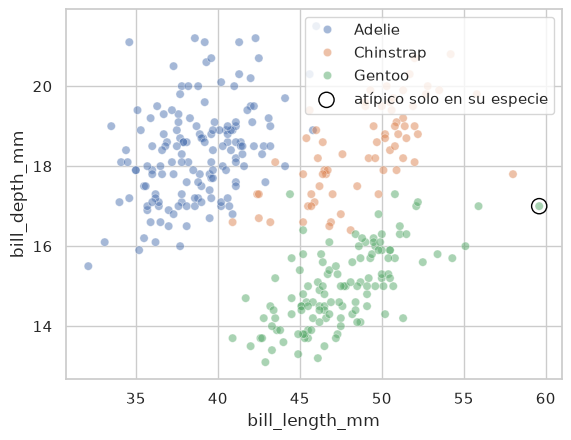

,species,sex,bill_length_mm,bill_depth_mm
252,Gentoo,Male,59.6,17.0


In [9]:
global_zr = atipicos_z_robusto(pinguinos["bill_length_mm"])
especie_zr = pinguinos.groupby("species")["bill_length_mm"].transform(atipicos_z_robusto)
solo_en_especie = especie_zr & ~global_zr
solo_global = global_zr & ~especie_zr
ax = sns.scatterplot(pinguinos, x="bill_length_mm", y="bill_depth_mm", hue="species", alpha=0.5)
ax.scatter(pinguinos.loc[solo_en_especie, "bill_length_mm"], pinguinos.loc[solo_en_especie, "bill_depth_mm"],
           s=120, facecolors="none", edgecolors="black", label="atípico solo en su especie")
ax.legend()
plt.show()
pinguinos.loc[solo_en_especie | solo_global, ["species", "sex", "bill_length_mm", "bill_depth_mm"]]

**✅ Respuesta sugerida:**

Un macho Gentoo con pico de 59.6 mm (el más largo del *dataset*) es atípico dentro de su especie (*z* robusto ≈ 3.95), pero no en el conjunto global, porque la distribución global de `bill_length_mm` es ancha al incluir a los Chinstrap y Gentoo de pico largo. Mezclar grupos **enmascara** atípicos: por eso se buscan dentro de cada grupo.

📖 **Para profundizar (opcional).** *Las tres reglas de atípicos en símbolos (sección 1).* Con $\bar{x}$ la media, $s$ la desviación estándar, $\tilde{x}$ la mediana y $Q_1$, $Q_3$ los cuartiles:

$$z_i = \frac{x_i - \bar{x}}{s} \qquad z^{\text{robusto}}_i = \frac{x_i - \tilde{x}}{MAD} \qquad \text{IQR: } x_i \notin [Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$$

**💡 Ideas clave de la sección 1:**
* Atípico no es sinónimo de error: se investiga antes de decidir.
* El puntaje *z* clásico sufre enmascaramiento; el *z* robusto y el IQR resisten la contaminación.
* Conviene buscar atípicos también **dentro** de cada grupo.

---
## 2. Transformaciones (15 min).

Muchas variables positivas (ingresos, precios, tiempos, tamaños de población) tienen **asimetría positiva** fuerte: la mayoría de los valores son pequeños y unos pocos son enormes. El **logaritmo** comprime la cola derecha:

* Convierte diferencias multiplicativas en aditivas (×10 pasa a ser +1 en `log10`).
* Reduce la asimetría y la influencia de los valores grandes.
* Solo se aplica a valores positivos; con ceros se usa `np.log1p(x)` = log(1 + x).
* Al volver a la escala original, la media de los logaritmos corresponde a la **media geométrica**, no a la media aritmética.

`penguins` es casi simétrico, así que se simularán ingresos mensuales con una distribución lognormal.

* La siguiente celda simulará 1,000 ingresos mensuales (en pesos) y su logaritmo base 10.

In [10]:
ingresos = pd.Series(rng.lognormal(mean=np.log(15000), sigma=0.8, size=1000), name="ingreso")
log_ingresos = np.log10(ingresos)
pd.DataFrame({
    "ingreso": [ingresos.skew(), ingresos.mean(), ingresos.median(), atipicos_iqr(ingresos).sum()],
    "log10(ingreso)": [log_ingresos.skew(), log_ingresos.mean(), log_ingresos.median(), atipicos_iqr(log_ingresos).sum()],
}, index=["asimetria", "media", "mediana", "atipicos IQR"]).round(2)

,ingreso,log10(ingreso)
asimetria,2.31,-0.04
media,20065.53,4.16
mediana,14918.90,4.17
atipicos IQR,63.00,4.00


**Interpretación:** en pesos, la asimetría es 2.31, la media (20,066) supera en un tercio a la mediana (14,919) y la regla del IQR marca 63 "atípicos". En escala logarítmica (`log10`, donde cada unidad equivale a multiplicar por 10), la asimetría es prácticamente 0, media y mediana coinciden y quedan solo 4 marcas. Los datos son los mismos; la escala cambia lo que parece extremo.

* La siguiente celda comparará ambas distribuciones gráficamente.

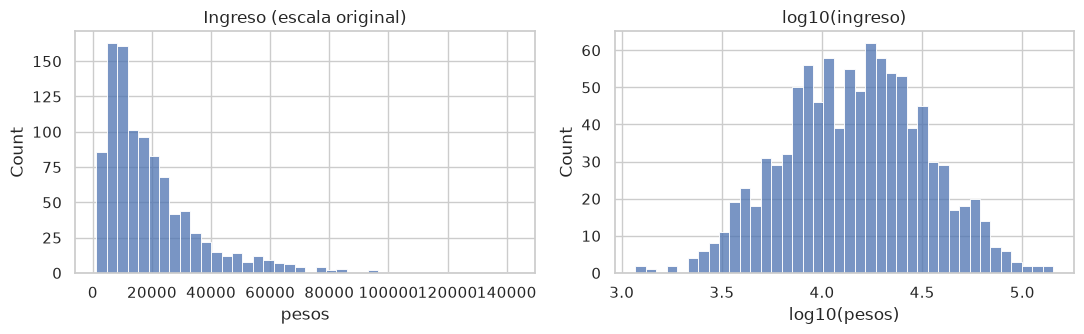

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(ingresos, bins=40, ax=axes[0]).set(title="Ingreso (escala original)", xlabel="pesos")
sns.histplot(log_ingresos, bins=40, ax=axes[1]).set(title="log10(ingreso)", xlabel="log10(pesos)")
plt.tight_layout()
plt.show()

* La siguiente celda comparará la media aritmética con la media geométrica (10 elevado a la media de los logaritmos).

In [12]:
{"media aritmética": round(ingresos.mean()), "media geométrica": round(10 ** log_ingresos.mean()), "mediana": round(ingresos.median())}

{'media aritmética': 20066, 'media geométrica': 14602, 'mediana': 14919}

**Interpretación:** la media geométrica (se promedian los ingresos en escala logarítmica y el resultado se regresa a pesos: unos 14,602 pesos) queda junto a la mediana, mientras que la aritmética (20,066) la arrastran los ingresos altos. Para variables multiplicativas y asimétricas, la media geométrica o la mediana describen mejor el "ingreso típico".

En la escala original, la regla del IQR marca decenas de "atípicos" que son simplemente la cola natural de la distribución; en escala logarítmica casi desaparecen. Antes de declarar atípico un valor, conviene preguntarse en qué escala tiene sentido la variable.

### 🔴 Reto 2 · La tarifa del Titanic.

**🎯 Objetivo:** aplicar una transformación logarítmica a una variable real con ceros. **Qué se espera aprender:** cuándo usar `log1p` y cómo cambia la noción de atípico al cambiar de escala.

Con `titanic.csv`, compara la asimetría de `fare` y de `np.log1p(fare)`, cuenta los atípicos por la regla del IQR en cada escala y grafica ambas distribuciones. ¿Por qué se usa `log1p` y no `log`? ¿Los pasajeros con tarifas altas son errores?

* La siguiente celda muestra una solución posible.

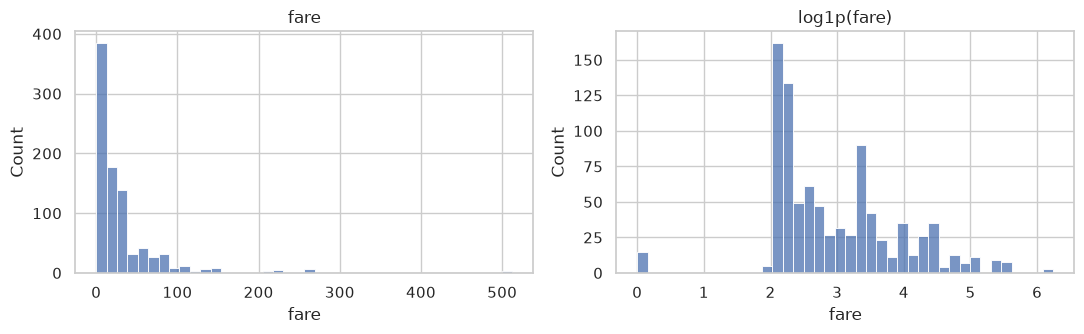

,fare,log1p(fare)
asimetria,4.79,0.39
atipicos IQR,116.00,31.00
tarifas en cero,15.00,NaN


In [13]:
tarifa = pd.read_csv(os.path.join(DATA, "titanic.csv"))["fare"]
log_tarifa = np.log1p(tarifa)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(tarifa, bins=40, ax=axes[0]).set(title="fare")
sns.histplot(log_tarifa, bins=40, ax=axes[1]).set(title="log1p(fare)")
plt.tight_layout()
plt.show()
pd.DataFrame({"fare": [tarifa.skew(), atipicos_iqr(tarifa).sum(), (tarifa == 0).sum()],
              "log1p(fare)": [log_tarifa.skew(), atipicos_iqr(log_tarifa).sum(), np.nan]},
             index=["asimetria", "atipicos IQR", "tarifas en cero"]).round(2)

**✅ Respuesta sugerida:**

La asimetría baja de 4.79 a 0.39 y los atípicos por IQR de 116 a 31. Se usa `log1p` porque hay 15 tarifas en cero y `log(0)` es −∞. Las tarifas altas (hasta 512 libras) corresponden a camarotes de primera clase: son la cola natural de una variable de precios, no errores. Las tarifas en cero sí merecen revisión (pueden ser tripulación o boletos de cortesía).

**💡 Ideas clave de la sección 2:**
* El logaritmo comprime la cola derecha y vuelve aditivas las diferencias multiplicativas.
* `log1p` cuando hay ceros; la media de los logaritmos corresponde a la media geométrica.
* Antes de declarar un atípico, pregunta en qué escala tiene sentido la variable.

---
## 3. Ejercicio integrador (20 min).

### 🟢 Ejercicio 3 · Describe la masa corporal en un párrafo.

**🎯 Objetivo:** integrar centro, dispersión, forma y atípicos en una descripción. **Qué se espera aprender:** a redactar la descripción de una variable como se pedirá en la Evaluación 1.

Con los resultados del ejercicio 2 de `10_tendencia_central_y_dispersion.ipynb`, de los ejercicios 1 y 2 de `11_forma_de_la_distribucion.ipynb` y de los ejercicios 1 y 2 de este *notebook*, redacta un párrafo de 4 a 6 frases que describa `body_mass_g`: centro y dispersión **por especie** (con las medidas adecuadas a la forma), forma de la distribución, por qué la distribución global engaña y qué atípicos hay. Usa números redondeados y unidades.

**✅ Respuesta sugerida:**

La masa corporal de los pingüinos depende sobre todo de la especie: los Gentoo pesan en promedio unos 5,080 g (desviación estándar ≈ 500 g), mientras que Adelie y Chinstrap rondan los 3,700 g (≈ 460 y 380 g). Dentro de cada especie la distribución es unimodal y casi simétrica, así que media y desviación estándar la describen bien. La distribución global, en cambio, es bimodal porque mezcla grupos: su media (4,200 g) no representa a ninguna especie. Dentro de cada especie solo la regla del IQR señala dos Chinstrap (2,700 y 4,800 g) como atípicos leves; son valores plausibles y se conservan.

---
## ✅ Cierre.

**Hoy vimos:**
* Medidas de centro y dispersión, y cuáles son **robustas** (mediana, IQR, MAD).
* La forma de una distribución: asimetría, curtosis y multimodalidad, y cuatro gráficas para verla.
* Que una distribución global bimodal suele ser la **mezcla de grupos**: hay que describir por especie.
* Tres reglas de valores atípicos y por qué el puntaje *z* clásico sufre **enmascaramiento**.
* La transformación logarítmica para variables con asimetría positiva.

**Práctica (sin calificación, en Classroom):** terminar los ejercicios 🟢 y, si es posible, un reto 🔴.

**Siguiente *notebook*:** `13_agregacion.ipynb`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>